
<h1 style="text-align: center;">Machine Learning Development Life Cycle</h1>


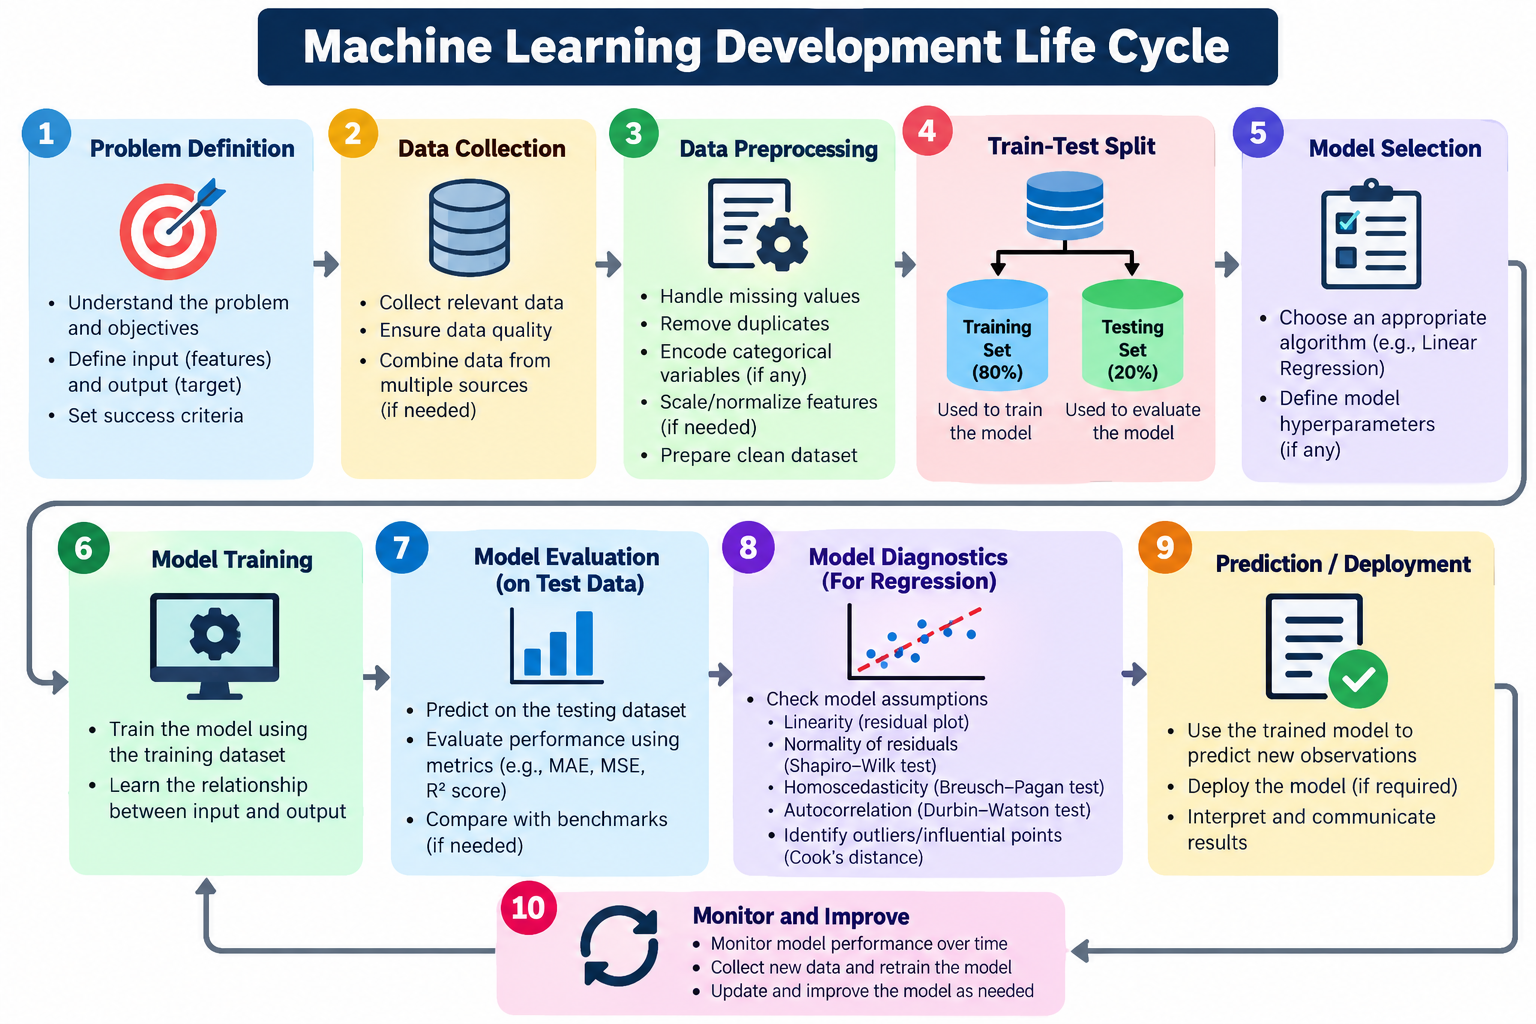

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv("placement.csv")

df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


# Calculate correlation

In [4]:
df["cgpa"].corr(df["package"])

np.float64(0.8806924693700491)

# Visualize correlation using a scatter plot

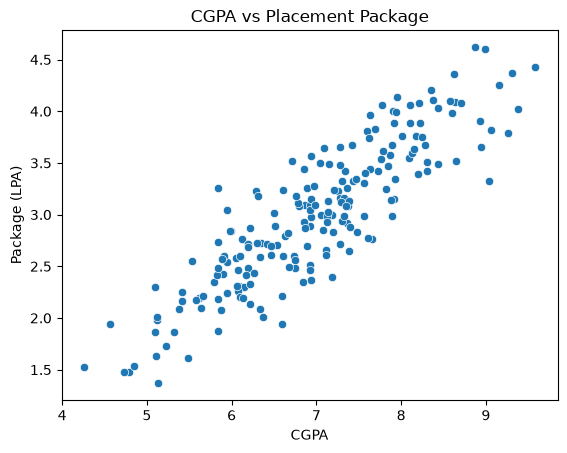

In [6]:
sns.scatterplot(df, x="cgpa", y="package")

plt.title("CGPA vs Placement Package")
plt.xlabel("CGPA")
plt.ylabel("Package (LPA)")
plt.show()


### Interpretation of Correlation Coefficient (r)

| Correlation (r) | Interpretation |
|---|---|
| +1 | Perfect positive correlation |
| +0.70 to +0.99 | Strong positive correlation |
| +0.30 to +0.69 | Moderate positive correlation |
| >0 to +0.29 | Weak positive correlation |
| 0 | No linear correlation |
| -0.29 to <0 | Weak negative correlation |
| -0.69 to -0.30 | Moderate negative correlation |
| -0.99 to -0.70 | Strong negative correlation |
| -1 | Perfect negative correlation |


# Define independent and dependent variables

In [7]:
X = df[["cgpa"]]
y = df["package"]

In [8]:
# Here, X is CGPA (independent variable) and y is package (dependent variable).

# Split into training and testing datasets

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

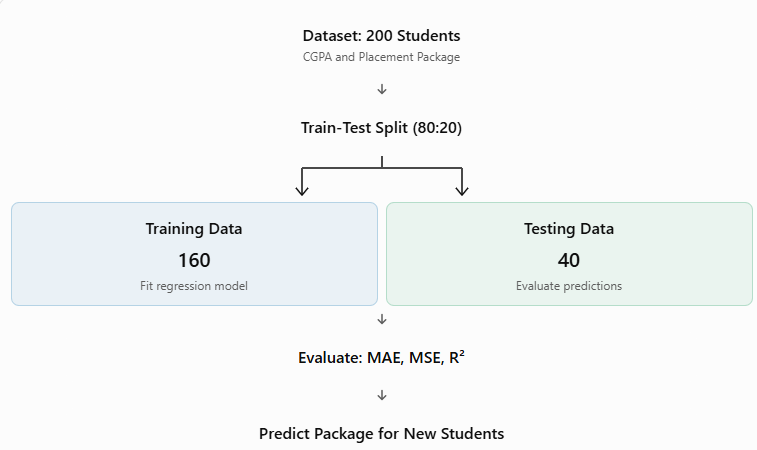


### Training and Testing Dataset

| Dataset | Percentage | Observations |
|---|---|---|
| Training | 80% | 160 |
| Testing | 20% | 40 |
| **Total** | **100%** | **200** |

### Explanation

- `test_size=0.2` reserves **20% of observations** for testing.
- `random_state=42` ensures the **same random split** whenever the code is executed.
- The model **learns from training data** and is **evaluated on testing data**.
- 
random_state is used to make sure that we get the same random selection of data every time we run the code.


In [10]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (160, 1)
Testing: (40, 1)


# Train the Linear Regression model

In [11]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.57]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['cgpa']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.027
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [12]:
# The model learns the relationship between CGPA and package using only the 160 training observations.

# Find the regression equation

In [13]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: -1.02700693745421
Coefficient: 0.5742564727019196



### Estimated Linear Regression Equation

The estimated equation is:

$$
\widehat{Package} = b_0 + b_1(CGPA)
$$


# Predict using testing data

In [14]:
y_pred = model.predict(X_test)

In [15]:
# Compare actual and predicted packages:

In [16]:
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

results.head(10)

,Actual,Predicted
95,2.79,2.780313
15,3.23,3.136352
30,3.26,3.199521
158,3.04,2.389819
128,3.34,3.526847
115,4.21,3.768035
69,2.94,3.165065
170,2.87,2.544868
174,2.99,3.176550
45,3.58,3.492392


# Evaluate model performance

In [17]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R-squared:", r2_score(y_test, y_pred))

MAE: 0.23150985393278373
MSE: 0.08417638361329657
R-squared: 0.7730984312051673



### Model Evaluation Metrics

| Metric | Meaning | Preferred Result |
|---|---|---|
| **MAE (Mean Absolute Error)** | Average absolute prediction error | Lower |
| **MSE (Mean Squared Error)** | Average squared prediction error | Lower |
| **R² (R-Squared)** | How well CGPA explains variation in package on the test data | Higher (maximum 1) |

### Interpretation

- **MAE:** Measures the average absolute difference between actual and predicted values.
- **MSE:** Measures the average squared difference between actual and predicted values. It penalizes larger errors more heavily.
- **R²:** Measures how well the regression model explains variation in the dependent variable (Package).

**Example:** If MAE = 0.30 and Package is measured in LPA (Lakhs Per Annum), the model's predictions differ from actual packages by approximately **₹0.30 LPA (₹30,000 per annum)** on average.


# Visualize training and testing data

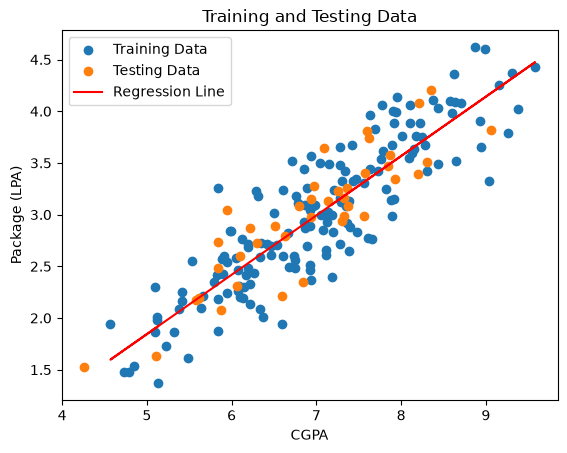

In [18]:
plt.scatter(X_train["cgpa"], y_train, label="Training Data")
plt.scatter(X_test["cgpa"], y_test, label="Testing Data")

plt.plot(
    X_train["cgpa"],
    model.predict(X_train),
    color="red",
    label="Regression Line"
)

plt.xlabel("CGPA")
plt.ylabel("Package (LPA)")
plt.title("Training and Testing Data")
plt.legend()
plt.show()

# Predict package for a new student

In [19]:
new_student = pd.DataFrame({"cgpa": [8.5]})

model.predict(new_student)

array([3.85417308])

# Correlation measures the relationship between CGPA and package, while regression learns from the training data and predicts placement packages for students it has not seen during training

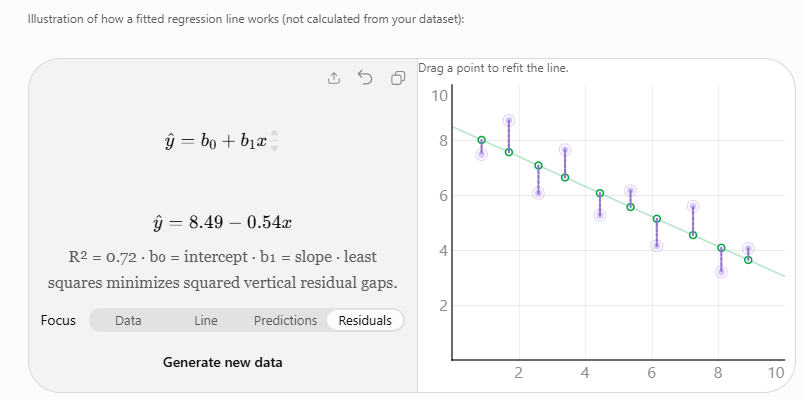

# Diagnostic tests


## Important Diagnostic Tests

| Diagnostic Test | Purpose | Python Method |
|---|---|---|
| **Linearity** | Checks whether the relationship is approximately linear | Residual plot |
| **Normality of Residuals** | Checks whether residuals follow a normal distribution | Shapiro–Wilk test |
| **Homoscedasticity** | Checks whether error variance is constant | Breusch–Pagan test |
| **Autocorrelation** | Checks whether residuals are serially correlated | Durbin–Watson statistic |
| **Multicollinearity** | Checks correlation among independent variables | VIF (Variance Inflation Factor) |
| **Outliers and Influential Observations** | Identifies unusual or influential observations | Cook's distance |

### Explanation

- **Linearity:** The relationship between independent and dependent variables should be approximately linear.
- **Normality of Residuals:** Residuals should be approximately normally distributed for certain statistical inference procedures.
- **Homoscedasticity:** The variance of errors should remain constant across different levels of predicted values.
- **Autocorrelation:** Residuals should not exhibit serial correlation.
- **Multicollinearity:** Independent variables should not be highly linearly related to one another.
- **Outliers and Influential Observations:** Unusual observations should be examined because they may strongly influence regression estimates.

**Note:** Multicollinearity is not applicable to simple linear regression with only one independent variable (e.g., CGPA predicting Package).


# Linearity test (Residual plot)

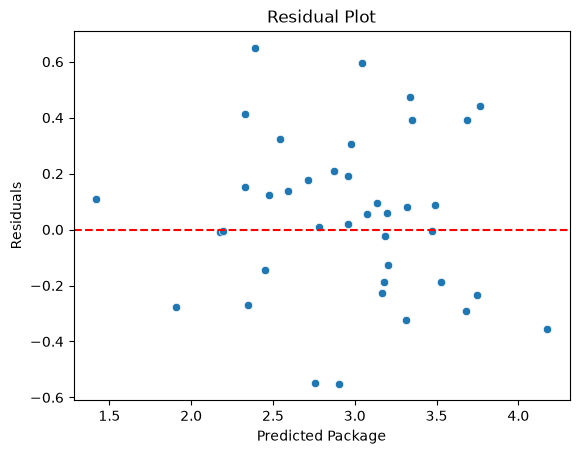

In [20]:
residuals = y_test - y_pred

sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Package")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()

Interpretation:
- Random scatter around zero → Linear model may be appropriate.
- Curved pattern → Possible nonlinear relationship.
- Funnel-shaped pattern → Possible heteroscedasticity.

# Normality test (Shapiro-Wilk)

In [21]:
from scipy.stats import shapiro

stat, p = shapiro(residuals)

print("P-value:", p)

P-value: 0.8182723402858333



### Normality of Residuals: Shapiro-Wilk Test

**Hypotheses:**

- **H₀ (Null Hypothesis):** Residuals follow a normal distribution.
- **H₁ (Alternative Hypothesis):** Residuals do not follow a normal distribution.

### Decision Rule

| P-value | Interpretation |
|---|---|
| **p > 0.05** | Fail to reject H₀ (Normality is not rejected) |
| **p ≤ 0.05** | Reject H₀ (Evidence against normality) |

### Test Result

**Obtained P-value = 0.8182723402858333**

**Significance Level (α) = 0.05**

Since **0.8183 > 0.05**, we **fail to reject the null hypothesis (H₀)**.

### Interpretation

The Shapiro–Wilk test produces a **p-value of 0.8183**, which is greater than the 5% significance level.

This indicates that there is **insufficient statistical evidence to conclude that the residuals deviate from a normal distribution**.

Therefore, the residuals are **consistent with the normality assumption**.

### Conclusion

The regression model **does not show evidence of violating the normality assumption** based on the Shapiro–Wilk test.

**Note:** Failing to reject H₀ does not prove that residuals are perfectly normally distributed. Normality is mainly relevant for exact small-sample statistical inference and is not a strict requirement for making predictions.


# Heteroscedasticity test (Breusch-Pagan)

For formal regression diagnostics, it is preferable to examine the training residuals using a model fitted to the training data.

In [22]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

X_train_sm = sm.add_constant(X_train)

ols_model = sm.OLS(y_train, X_train_sm).fit()

bp_test = het_breuschpagan(
    ols_model.resid,
    ols_model.model.exog
)

print("P-value:", bp_test[1])

P-value: 0.31195642201096424



### Homoscedasticity: Breusch–Pagan Test

**Hypotheses:**

- **H₀ (Null Hypothesis):** Homoscedasticity (constant error variance).
- **H₁ (Alternative Hypothesis):** Heteroscedasticity (nonconstant error variance).

### Decision Rule

| P-value | Interpretation |
|---|---|
| **p > 0.05** | Fail to reject H₀ (No statistically significant evidence of heteroscedasticity) |
| **p ≤ 0.05** | Reject H₀ (Evidence of heteroscedasticity) |

### Test Result

**Obtained P-value = 0.31195642201096424**

**Significance Level (α) = 0.05**

Since **0.3120 > 0.05**, we **fail to reject the null hypothesis (H₀)**.

### Interpretation

The Breusch–Pagan test produces a **p-value of 0.3120**, which is greater than the 5% significance level.

This indicates that there is **insufficient statistical evidence to conclude that the error variance is nonconstant**.

Therefore, the regression model does not show statistically significant evidence of heteroscedasticity.

### Conclusion

The regression model **does not show evidence of violating the homoscedasticity assumption** based on the Breusch–Pagan test.

In the context of **CGPA and Placement Package**, this suggests that there is no statistically significant evidence that the variability of regression errors changes systematically with CGPA.

**Example:** The test does not provide sufficient evidence that placement package errors vary more among high-CGPA students than among low-CGPA students.

**Note:** Failing to reject H₀ does not prove that the error variance is perfectly constant. It only indicates that the test did not detect statistically significant heteroscedasticity.


# Normal Q-Q plot

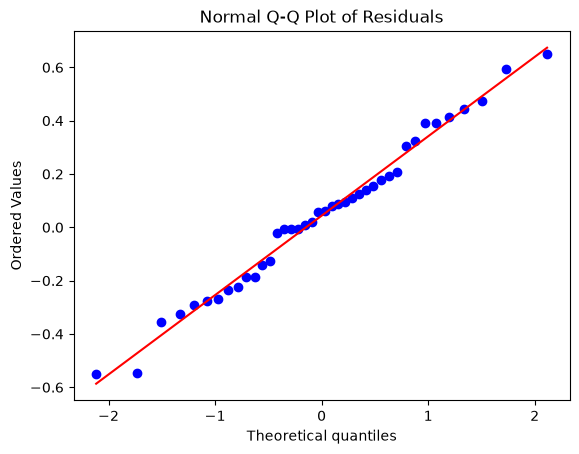

In [24]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot of Residuals")
plt.show()


### Interpretation of Normal Q–Q Plot of Residuals

The Normal Q–Q (Quantile–Quantile) plot is used to visually examine whether the residuals of a regression model follow a normal distribution.

### Interpretation

- **Red Diagonal Line:** Represents the expected distribution of residuals under normality.
- **Blue Dots:** Represent the observed residual quantiles.
- **Middle Region:** Most blue dots lie very close to the red diagonal line, indicating that the residuals approximately follow a normal distribution.
- **Tails:** A few observations show minor deviations from the diagonal line, but these deviations are not substantial.
- **Overall Pattern:** The blue dots closely follow the diagonal line, suggesting that the residuals are approximately normally distributed.

### Comparison with Shapiro–Wilk Test

| Method | Result | Interpretation |
|---|---|---|
| **Shapiro–Wilk Test** | p = 0.8183 > 0.05 | Fail to reject the null hypothesis of normality |
| **Normal Q–Q Plot** | Most points lie close to the diagonal line | Residuals appear approximately normally distributed |

### Conclusion

Both the **Shapiro–Wilk test (p = 0.8183)** and the **Normal Q–Q plot** provide consistent evidence that the residuals are approximately normally distributed.

Therefore, the regression model **does not show evidence of violating the normality assumption**.

**Note:** The Q–Q plot provides visual evidence, while the Shapiro–Wilk test provides statistical evidence. Neither method proves perfect normality.


# Durbin-Watson Test
The Durbin–Watson test checks whether regression residuals are correlated with residuals from the preceding observation.
Hypotheses
- H₀: No first-order autocorrelation.
- H₁: First-order autocorrelation exists.

In [26]:
from statsmodels.stats.stattools import durbin_watson

dw = durbin_watson(ols_model.resid)

print("Durbin-Watson Statistic:", dw)

Durbin-Watson Statistic: 1.9939636046040685



### Autocorrelation: Durbin–Watson Test

The Durbin–Watson test is used to detect **first-order autocorrelation among the residuals** of a regression model.

### Hypotheses

- **H₀ (Null Hypothesis):** There is no first-order autocorrelation among the residuals.
- **H₁ (Alternative Hypothesis):** There is first-order autocorrelation among the residuals.

### Interpretation

| Durbin–Watson Statistic | Interpretation |
|---|---|
| **Close to 0** | Strong positive autocorrelation |
| **Below 2** | Indicates positive autocorrelation |
| **Approximately 2** | No first-order autocorrelation |
| **Above 2** | Indicates negative autocorrelation |
| **Close to 4** | Strong negative autocorrelation |

### Test Result

**Obtained Durbin–Watson Statistic = 1.9939636046040685**

### Interpretation of the Result

The Durbin–Watson statistic is **1.9940**, which is very close to **2**.

This indicates that there is **little to no evidence of first-order autocorrelation among the residuals**.

Therefore, the regression residuals do not exhibit a meaningful pattern of positive or negative first-order serial correlation.

### Conclusion

The Durbin–Watson statistic of **1.9940** suggests that the regression model **does not show evidence of violating the no first-order autocorrelation assumption**.

In the context of **CGPA and Placement Package**, this suggests that the prediction errors do not exhibit first-order serial correlation in the order in which the observations were analysed.

**Note:** The Durbin–Watson statistic ranges from 0 to 4. A value close to 2 indicates little or no first-order autocorrelation. These are general guidelines; formal significance testing requires appropriate critical values. For cross-sectional data, the interpretation also depends on whether the ordering of observations is meaningful.
